# RFI suppression with alternating projections (Huang et al., TGRS 2022)

Same structure as `process_rfi.ipynb`: config, product selection, filter loop with `plot_result`, metrics sweep,
comparison with Lambda-1/BSF. The method is implemented in `src/rfi_ap.py` (numpy/scipy only).

**Idea.** RFI is a low-rank matrix in the 2-D frequency domain of the SLC image, while the focused scene is sparse in
the image domain. `min rank(R) + lam*||X||_1  s.t.  F(Y) = R + F(X)` is solved by ADMM; the rank-r projection of `R`
uses QR decompositions and a 2r x 2r SVD instead of an SVD of the full matrix. The output is `Y - F^-1(R)`.

**What is ours, not the paper's:** the paper does not say how to choose `lam, mu0, rho, eta` (RPCA defaults used), it
estimates the rank by MDL on a Sentinel-1 crop (plain MDL returns ~min(K, L) on a BIOMASS scene; the default here counts the eigenvalues of the *whitened* spectrum 5x above
the noise edge, `rank_rule="mdl"` gives MDL on the whitened spectrum), and the scene is
processed in strips of azimuth lines.

In [1]:
%load_ext autoreload
%autoreload 2

import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from rasterio.windows import Window
from scipy.ndimage import median_filter
from tqdm import tqdm

import rfi_mitigation as rm  # Lambda-1 + BSF, only for the comparison
from plotting import plot_result
from processing import read_item
from rfi_ap import ap_filter

cfg_file = Path("../config.yaml").resolve()
cfg = yaml.safe_load(cfg_file.read_text())
data_path = Path(cfg["paths"]["data"])
out_path = Path(cfg["paths"]["output"])

POLS = ["HH", "HV", "VH", "VV"]  # assumed band order, check src.descriptions or the annotation XML

## Products
Products already downloaded in `data_path` (same ids as in `process_rfi.ipynb`, no STAC query needed).

In [2]:
selected = [
    "BIO_S3_SCS__1S_20260829T233255_20260829T233313_T_G01_M04_C05_T044_F162_02_DWYO99",
    "BIO_S3_SCS__1S_20260829T233236_20260829T233257_T_G01_M04_C05_T044_F161_02_DWYO8H",
    "BIO_S3_SCS__1S_20260829T233217_20260829T233238_T_G01_M04_C05_T044_F160_02_DWYO38",
    "BIO_S3_SCS__1S_20260829T233158_20260829T233219_T_G01_M04_C05_T044_F159_02_DWYO4X",
    "BIO_S3_SCS__1S_20260829T233139_20260829T233200_T_G01_M04_C05_T044_F158_02_DWYO5W",
    "BIO_S3_SCS__1S_20260829T233120_20260829T233141_T_G01_M04_C05_T044_F157_02_DWYO5M",
    "BIO_S3_SCS__1S_20260829T233101_20260829T233122_T_G01_M04_C05_T044_F156_02_DWYO3C",
    "BIO_S3_SCS__1S_20260829T233042_20260829T233103_T_G01_M04_C05_T044_F155_02_DWYOAL",
    "BIO_S3_SCS__1S_20260829T233023_20260829T233044_T_G01_M04_C05_T044_F154_02_DWYO9B",
    "BIO_S3_SCS__1S_20260829T233004_20260829T233025_T_G01_M04_C05_T044_F153_02_DWYOAY",
]
ids = sorted(p.name for p in data_path.iterdir() if p.is_dir())
N = len(selected)  # number of products to process
ids_selected = [i for i in selected if i in ids][:N] or ids[:N]

paths_by_id = {
    i: {
        "enclosure_annot_xml": next((data_path / i).glob("*_annot.xml")),
        "enclosure_i_abs_tiff": next((data_path / i).glob("*_i_abs.tiff")),
        "enclosure_i_phase_tiff": next((data_path / i).glob("*_i_phase.tiff")),
    }
    for i in ids_selected
}
print(f"{len(ids_selected)} products to process")

10 products to process


## Run the filter
`ap_filter` works per polarization and per strip of `strip` azimuth lines over the full range (the matrix of one strip is
`strip x 1383`). `rank=None` estimates the rank from the whitened spectrum (edge rule; `rank_rule="mdl"` for MDL); `rank=25` fixes it.

  0%|          | 0/10 [00:00<?, ?it/s]

BIO_S3_SCS__1S_20260829T233255_20260829T233313_T_G01_M04_C05_T044_F162_02_DWYO99: 43 s
   pol         rows  rank  iters  final_err
0   HH       0-4096     4     11   0.000080
1   HH    4096-8192     4     11   0.000078
2   HH   8192-12288     4     11   0.000079
3   HH  12288-17976     4     11   0.000068
4   HV       0-4096     5     12   0.000046
5   HV    4096-8192     5     11   0.000078
6   HV   8192-12288     6     11   0.000080
7   HV  12288-17976     7     11   0.000080
8   VH       0-4096     5     11   0.000078
9   VH    4096-8192     5     11   0.000075
10  VH   8192-12288     6     11   0.000080
11  VH  12288-17976     7     11   0.000071
12  VV       0-4096     4     11   0.000078
13  VV    4096-8192     4     11   0.000079
14  VV   8192-12288     4     11   0.000074
15  VV  12288-17976     4     11   0.000065


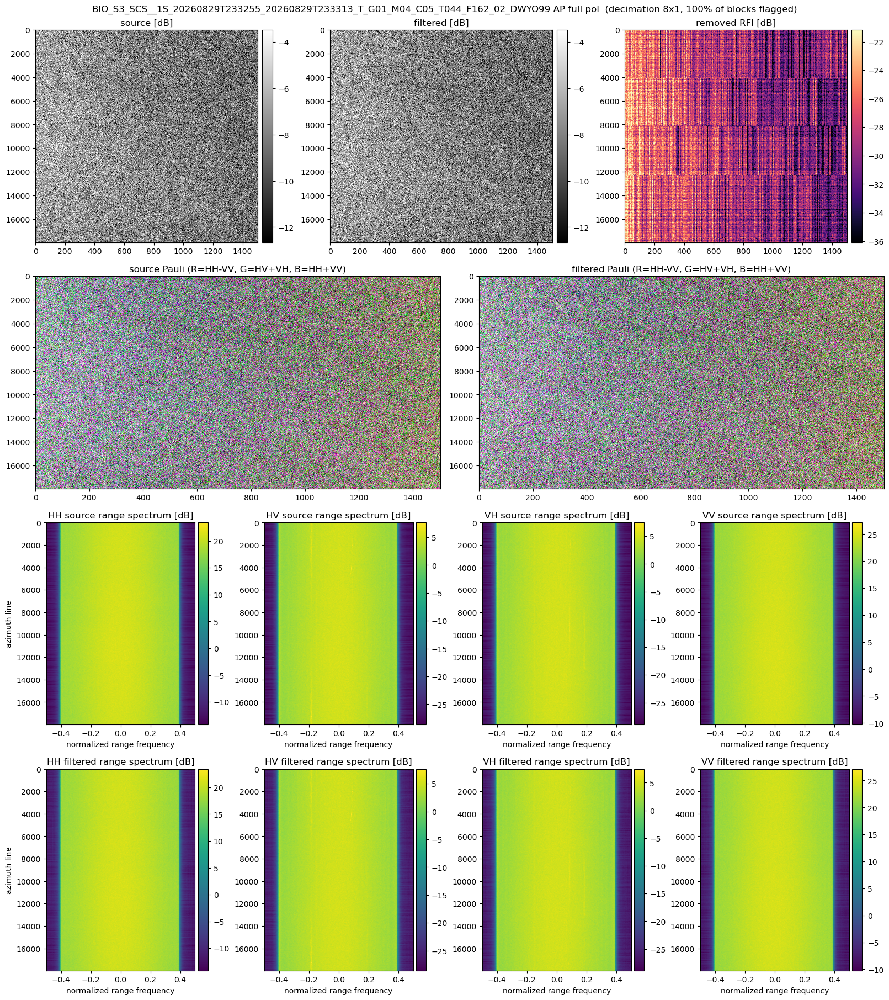

 10%|█         | 1/10 [01:04<09:40, 64.48s/it]

BIO_S3_SCS__1S_20260829T233236_20260829T233257_T_G01_M04_C05_T044_F161_02_DWYO8H: 57 s
   pol         rows  rank  iters  final_err
0   HH       0-4096     9     11   0.000089
1   HH    4096-8192     9     11   0.000094
2   HH   8192-12288     9     11   0.000097
3   HH  12288-16384     8     11   0.000095
4   HH  16384-20775     8     11   0.000088
5   HV       0-4096     6     11   0.000085
6   HV    4096-8192     6     11   0.000086
7   HV   8192-12288     7     11   0.000085
8   HV  12288-16384     7     11   0.000084
9   HV  16384-20775     7     12   0.000052
10  VH       0-4096     7     11   0.000082
11  VH    4096-8192     7     11   0.000091
12  VH   8192-12288     8     11   0.000089
13  VH  12288-16384     8     11   0.000086
14  VH  16384-20775     7     11   0.000078
15  VV       0-4096     9     11   0.000090
16  VV    4096-8192     9     11   0.000091
17  VV   8192-12288     9     11   0.000093
18  VV  12288-16384     7     11   0.000088
19  VV  16384-20775     8     11 

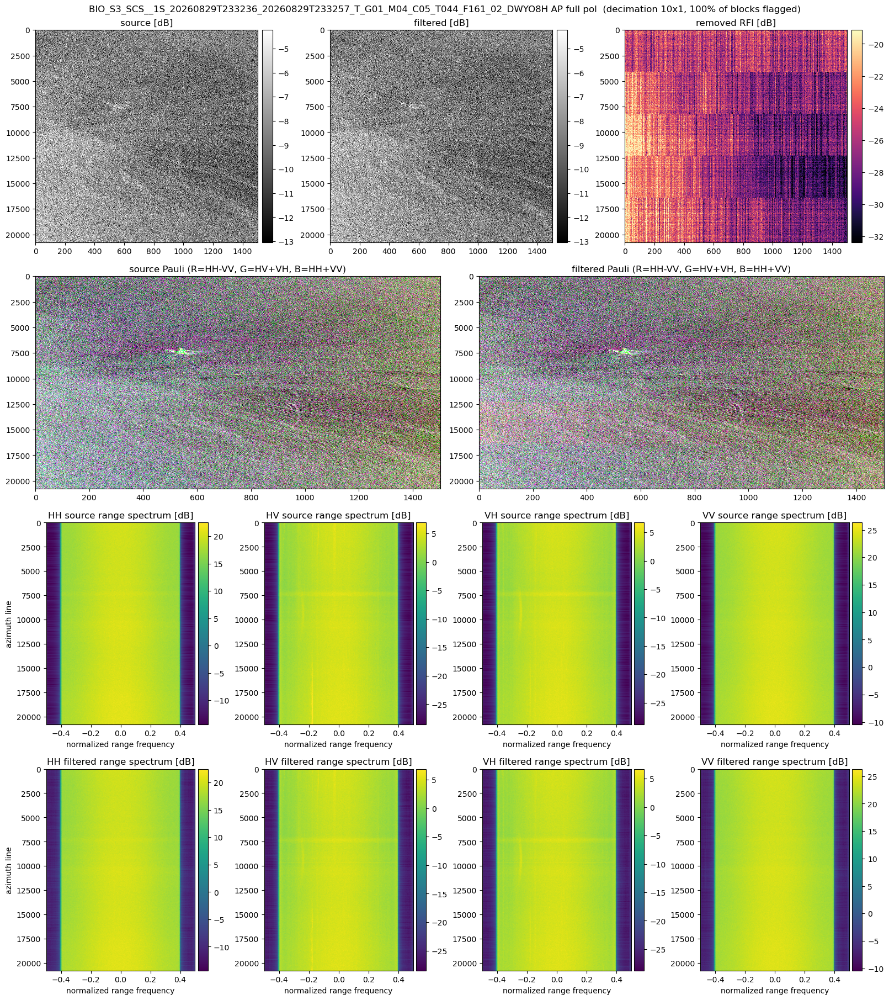

 20%|██        | 2/10 [02:25<09:53, 74.15s/it]

BIO_S3_SCS__1S_20260829T233217_20260829T233238_T_G01_M04_C05_T044_F160_02_DWYO38: 60 s
   pol         rows  rank  iters  final_err
0   HH       0-4096     5     12   0.000056
1   HH    4096-8192     5     13   0.000069
2   HH   8192-12288     5     14   0.000064
3   HH  12288-16384     9     15   0.000071
4   HH  16384-20774    12     12   0.000064
5   HV       0-4096     5     13   0.000046
6   HV    4096-8192     5     12   0.000060
7   HV   8192-12288     6     12   0.000071
8   HV  12288-16384     5     13   0.000097
9   HV  16384-20774    12     12   0.000051
10  VH       0-4096     5     13   0.000091
11  VH    4096-8192     5     12   0.000067
12  VH   8192-12288     5     12   0.000061
13  VH  12288-16384     5     13   0.000073
14  VH  16384-20774    12     12   0.000050
15  VV       0-4096     5     12   0.000062
16  VV    4096-8192     5     13   0.000076
17  VV   8192-12288     5     14   0.000060
18  VV  12288-16384     6     14   0.000091
19  VV  16384-20774    13     12 

In [ ]:
params = dict(strip=4096, rank=None, rmax=100)  # tweak here: rank=None (auto) or an int
full_pol = True  # (4, R, C): each pol is filtered on its own and plotted with the pol-summed power + Pauli RGB
selected_pol = "HV"
ch = POLS.index(selected_pol)

for item_id in tqdm(ids_selected):
    slc = read_item(item_id, paths_by_id)
    info = []
    t0 = time.time()
    clean, mask = ap_filter(slc if full_pol else slc[ch], info=info, **params)
    print(f"{item_id}: {time.time() - t0:.0f} s")
    print(
        pd.DataFrame(
            [dict(pol=POLS[k] if full_pol else selected_pol, rows=f"{a}-{b}", rank=i["rank"], iters=i["iters"],
                  final_err=i["err"][-1] if i["err"] else None) for k, a, b, i in info]
        ).to_string()
    )
    plot_result(
        slc if full_pol else slc[ch],
        clean,
        mask,
        max_px=2000,
        aspect="auto",
        title=f"{item_id} AP {'full pol' if full_pol else selected_pol}",
        out_dir=f"{out_path}/{item_id}_ap",
        spectrum=True,
    )
    del slc, clean, mask

## Metrics on a strip
One strip (4096 azimuth lines) of the first product, all four pols. No ground truth, so:
* `removed_frac`: removed energy / total energy;
* `line_sup_dB`: suppression of the strongest narrow RFI lines of the mean range spectrum (found automatically as
  peaks above a running-median baseline), mean over the 3 strongest;
* `notch_dB`: lowest value of (spectrum / running-median baseline) after filtering, i.e. over-removal (negative = notch);
* `rough_ratio`: streak metric of `process_rfi.ipynb` (row-power profile minus its running median, filtered / source).

In [ ]:
def range_profile(S):
    return (np.abs(np.fft.fftshift(np.fft.fft(S, axis=-1), axes=-1)) ** 2).mean(axis=-2)


def baseline(p):
    return median_filter(p, 151, mode="nearest")


def rfi_lines(S, n=3):
    f = np.fft.fftshift(np.fft.fftfreq(S.shape[-1]))
    p = range_profile(S)
    r = np.where(np.abs(f) < 0.38, p / baseline(p), 0)
    sel = []
    for i in np.argsort(r)[::-1][:80]:
        if r[i] > 3 and all(abs(i - j) > 8 for j in sel):
            sel.append(i)
    return sel[:n], r


def row_rough(S, k=101):
    p = 10 * np.log10((np.abs(S) ** 2).mean(axis=1) + 1e-12)
    return np.std(p - median_filter(p, k, mode="nearest"))


def evaluate(S, C, lines, r0):
    p1 = range_profile(C)
    r1 = p1 / baseline(p1)
    return dict(
        removed_frac=np.linalg.norm(S - C) ** 2 / np.linalg.norm(S) ** 2,
        line_sup_dB=np.mean([10 * np.log10(r0[i] / r1[i]) for i in lines]) if lines else np.nan,
        notch_dB=10 * np.log10(r1[np.abs(np.fft.fftshift(np.fft.fftfreq(S.shape[-1]))) < 0.38].min()),
        rough_ratio=row_rough(C) / row_rough(S),
    )


item_id = ids_selected[0]
row0 = 8000
S4 = read_item(item_id, paths_by_id, window=Window(0, row0, 1383, 4096))  # (4, 4096, 1383)
print(S4.shape)

(4, 4096, 1383)


In [ ]:
rows = []
for k, pol in enumerate(POLS):
    S = S4[k]
    lines, r0 = rfi_lines(S)
    for rank in (10, 25, 50, 100, None):
        info = []
        t0 = time.time()
        C, _ = ap_filter(S, strip=S.shape[0], rank=rank, info=info)
        rows.append(dict(pol=pol, rank=rank if rank else f"auto ({info[0][3]['rank']})", iters=info[0][3]["iters"],
                         time_s=time.time() - t0, **evaluate(S, C, lines, r0)))
df_rank = pd.DataFrame(rows)
df_rank.round(3)

,pol,rank,iters,time_s,removed_frac,line_sup_dB,notch_dB,rough_ratio
0,HH,10,15,2.908,0.100,5.667,-0.360,0.975
1,HH,25,16,2.995,0.150,6.856,-0.442,0.930
2,HH,50,17,3.521,0.215,7.315,-0.880,0.944
3,HH,100,18,4.056,0.328,7.617,-0.961,0.947
4,HH,auto (7),15,3.278,0.084,5.308,-0.371,1.046
5,HV,10,19,3.482,0.830,6.031,-0.458,0.815
6,HV,25,19,3.634,0.949,21.569,-3.050,0.233
7,HV,50,20,4.300,0.956,22.357,-3.780,0.235
8,HV,100,21,4.753,0.963,22.493,-3.788,0.240
9,HV,auto (23),19,4.169,0.948,21.597,-3.047,0.243


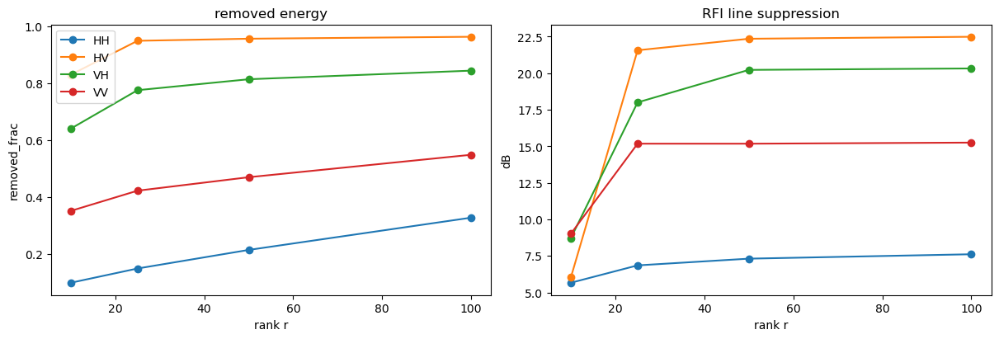

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for pol, g in df_rank[df_rank["rank"].map(lambda r: isinstance(r, int))].groupby("pol"):
    ax[0].plot(g["rank"], g.removed_frac, "o-", label=pol)
    ax[1].plot(g["rank"], g.line_sup_dB, "o-", label=pol)
ax[0].set(xlabel="rank r", ylabel="removed_frac", title="removed energy")
ax[1].set(xlabel="rank r", ylabel="dB", title="RFI line suppression")
ax[0].legend()
plt.show()

## Comparison with Lambda-1 + BSF (per channel) on the same strip

In [ ]:
p = rm.ups_bdr(paths_by_id[item_id]["enclosure_annot_xml"])
t0 = time.time()
L1, _ = rm.lambda1_bsf(S4, joint=False, gamma=1, ns_max=30, ns_mul=2, **p)
t_l1 = time.time() - t0
t0 = time.time()
AP, _ = ap_filter(S4, strip=S4.shape[1])
t_ap = time.time() - t0
rows = []
for k, pol in enumerate(POLS):
    lines, r0 = rfi_lines(S4[k])
    rows.append(dict(pol=pol, method="Lambda1-BSF", **evaluate(S4[k], L1[k], lines, r0)))
    rows.append(dict(pol=pol, method="AP (auto rank)", **evaluate(S4[k], AP[k], lines, r0)))
print(f"time for the 4 pols: Lambda1-BSF {t_l1:.0f} s | AP {t_ap:.0f} s")
pd.DataFrame(rows).round(3)

time for the 4 pols: Lambda1-BSF 3 s | AP 14 s


,pol,method,removed_frac,line_sup_dB,notch_dB,rough_ratio
0,HH,Lambda1-BSF,0.169,6.226,-0.604,1.092
1,HH,AP (auto rank),0.084,5.308,-0.371,1.046
2,HV,Lambda1-BSF,0.956,23.415,-5.912,0.225
3,HV,AP (auto rank),0.948,21.597,-3.047,0.243
4,VH,Lambda1-BSF,0.818,21.317,-6.126,0.300
5,VH,AP (auto rank),0.772,17.895,-2.680,0.342
6,VV,Lambda1-BSF,0.447,15.226,-2.306,1.092
7,VV,AP (auto rank),0.384,11.928,-0.406,1.042


## Ground-truth benchmark with injected RFI
There is no clean BIOMASS scene, so a real strip (HV, cleaned by Lambda-1/BSF, so it keeps the speckle and texture
statistics of the real data) is used as the *truth* `X`; a synthetic narrowband comb (30 lines in -0.36..-0.31 and 4 near
-0.16, azimuth-varying amplitudes, so a low-rank RFI matrix of rank <= 34) is added at a given SIR and removed again.
`error = ||X_hat - X|| / ||X||`; the polluted error is the error of doing nothing. The truth is itself the output of a
filter, so an HH scene cleaned by AP (rank 10) is also used to check the result is not biased toward one method. (An HV strip
cleaned by AP is not a valid truth: that strip is RFI-dominated and a low-rank cleaning leaves strong residual RFI in it.)

In [ ]:
rng = np.random.default_rng(1)
K, L = S4.shape[1:]
t, l = np.arange(L), np.arange(K)
freqs = np.concatenate([rng.uniform(-0.36, -0.31, 30), rng.uniform(-0.165, -0.155, 4)])
Rn = np.zeros((K, L), np.complex64)
for f in freqs:
    a = (1 + 0.5 * np.cos(2 * np.pi * rng.integers(1, 4) * l / K + rng.uniform(0, 6)))[:, None]
    Rn += (a * np.exp(2j * np.pi * (f * t + rng.random()))[None]).astype(np.complex64)

scenes = {
    "HV L1-cleaned": rm.lambda1_bsf(S4[1], gamma=1, ns_max=30, ns_mul=2, **p)[0],
    "HH L1-cleaned": rm.lambda1_bsf(S4[0], gamma=1, ns_max=30, ns_mul=2, **p)[0],
    "HH AP10-cleaned": ap_filter(S4[0], strip=K, rank=10)[0],
}
rows = []
for scene, X in scenes.items():
    X = X.astype(np.complex64)
    for sir in (-20, -10, 0):
        Y = (X + Rn * np.sqrt(10 ** (-sir / 10) * (np.abs(X) ** 2).mean() / (np.abs(Rn) ** 2).mean())).astype(np.complex64)
        err = lambda Z: np.linalg.norm(Z - X) / np.linalg.norm(X)
        res = {"polluted": err(Y)}
        for rank in (10, 25, 50, None):
            info = []
            res[f"AP r={rank}" if rank else "AP auto"] = err(ap_filter(Y, strip=K, rank=rank, info=info)[0])
            if rank is None:
                res["auto rank"] = info[0][3]["rank"]
        res["Lambda1-BSF"] = err(rm.lambda1_bsf(Y, gamma=1, ns_max=30, ns_mul=2, **p)[0])
        rows.append(dict(scene=scene, SIR_dB=sir, **res))
df_gt = pd.DataFrame(rows)
df_gt.round(3)

,scene,SIR_dB,polluted,AP r=10,AP r=25,AP r=50,AP auto,auto rank,Lambda1-BSF
0,HV L1-cleaned,-20,10.000,0.154,0.291,0.403,0.227,16,0.182
1,HV L1-cleaned,-10,3.162,0.149,0.280,0.395,0.216,16,0.201
2,HV L1-cleaned,0,1.000,0.155,0.294,0.405,0.186,12,0.252
3,HH L1-cleaned,-20,10.000,0.126,0.270,0.381,0.246,21,0.219
4,HH L1-cleaned,-10,3.162,0.161,0.275,0.379,0.250,21,0.175
5,HH L1-cleaned,0,1.000,0.167,0.274,0.374,0.227,17,0.165
6,HH AP10-cleaned,-20,10.000,0.137,0.258,0.370,0.240,22,0.218
7,HH AP10-cleaned,-10,3.162,0.145,0.258,0.370,0.239,22,0.192
8,HH AP10-cleaned,0,1.000,0.148,0.261,0.369,0.217,18,0.187


## Results and conclusions
(filled in after running, see below)